### Problem 1

#### Part 1.1

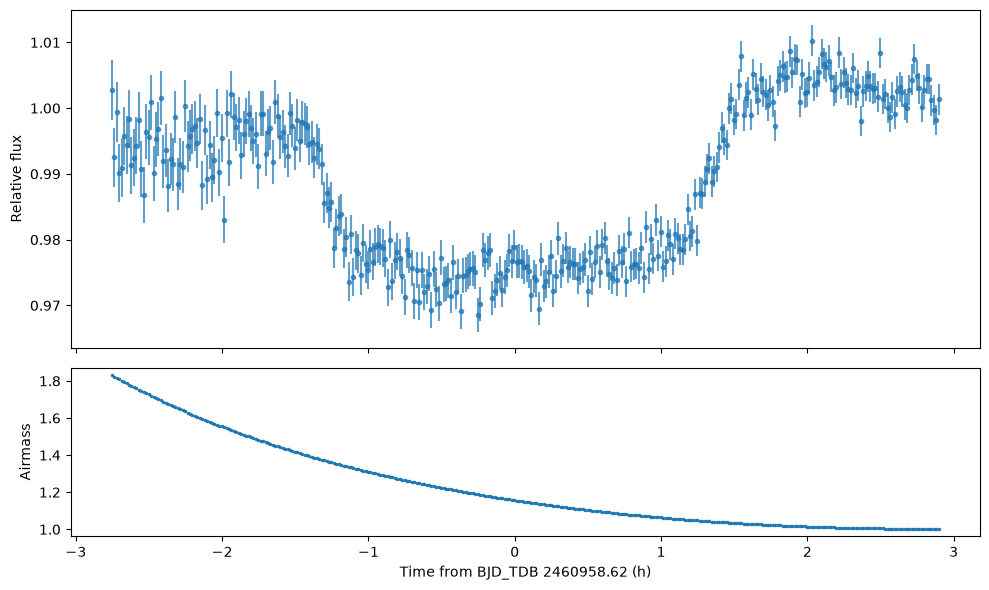

In [11]:
# Plot relative flux vs. time, with airmass beneth it on a seperate panel.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit
from scipy.stats import ttest_ind

# Allow running from either the pset7 folder or the repo root.
data_dir = Path("P7_transit")
if not data_dir.is_dir():
    data_dir = Path("pset7/P7_transit")
data = np.genfromtxt(data_dir / "HAT-P-32_2025-10-10.csv",
                     delimiter=",", names=True, dtype=None, encoding="utf-8")
bjd_ref = 2460958.62
time = 24 * (data["bjd_tdb"] - bjd_ref)
flux, err, airmass = data["flux"], data["err"], data["airmass"]

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6),
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].errorbar(time, flux, yerr=err, fmt=".", alpha=0.7)
axes[0].set_ylabel("Relative flux")
axes[1].plot(time, airmass, ".", markersize=3)
axes[1].set_ylabel("Airmass")
axes[1].set_xlabel(f"Time from BJD_TDB {bjd_ref:.2f} (h)")
fig.tight_layout()
plt.show()


##### 1.1 Written

A good $H_0$ here might be: we predict that there is no eclipse of HAT-P-32. This model would predict a constant light curve. We fit a constant model below and discuss implications thereafter. 

Constant level = 0.988670 +/- 0.000144
chi^2_const = 7575.37, dof = 339
Reduced chi^2_const = 22.346
Eq. (3): t = 277.911, log10(alpha) = -16773.82


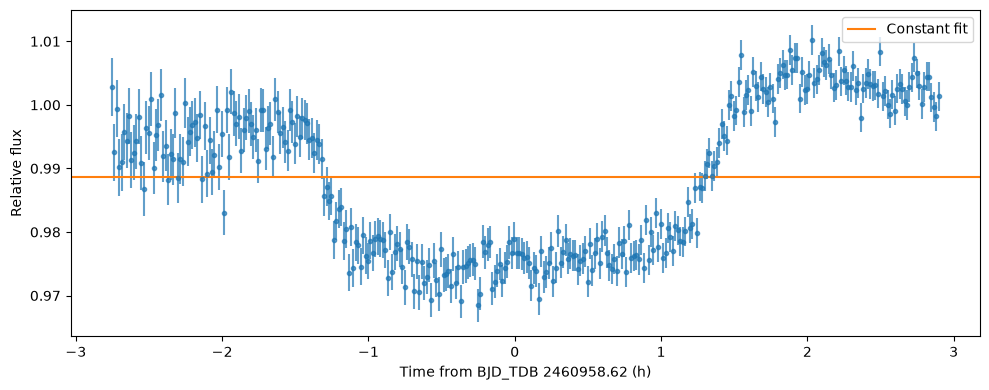

In [12]:
# Fit model from written and compute reduced chi^2
# Constant-flux null model, using the supplied uncertainties.
def constant_model(t, level):
    return np.full_like(t, level, dtype=float)

const_params, const_cov = curve_fit(constant_model, time, flux,
                                    sigma=err, absolute_sigma=True, p0=[1.0])
const_level = const_params[0]
chi2_const = np.sum(((flux - constant_model(time, const_level)) / err)**2)
dof_const = len(flux) - 1
from scipy.special import log_ndtr

t_const = (chi2_const / dof_const - 1) / np.sqrt(2 / dof_const)
# Evaluate the Eq. (2) Gaussian tail in log space to avoid underflow.
log10_alpha_const = (np.log(2) + log_ndtr(-abs(t_const))) / np.log(10)
print(f"Constant level = {const_level:.6f} +/- {np.sqrt(const_cov[0, 0]):.6f}")
print(f"chi^2_const = {chi2_const:.2f}, dof = {dof_const}")
print(f"Reduced chi^2_const = {chi2_const / dof_const:.3f}")
print(f"Eq. (3): t = {t_const:.3f}, log10(alpha) = {log10_alpha_const:.2f}")

plt.figure(figsize=(10, 4))
plt.errorbar(time, flux, yerr=err, fmt=".", alpha=0.7)
plt.axhline(const_level, color="C1", label="Constant fit")
plt.xlabel(f"Time from BJD_TDB {bjd_ref:.2f} (h)")
plt.ylabel("Relative flux")
plt.legend()
plt.tight_layout()
plt.show()


##### 1.1 Written (again)

The constant level is 0.98867 $\pm$ 0.00014, with $\chi_\nu^2 = 22.346$. Eq. (3) gives $t = 277.911$; the Gaussian approximation in Eq. (2) gives $\log_{10}\alpha = -16773.82$, which is too small to represent directly as a floating-point probability. So we have highly significant evidence to reject $H_0$, assuming the stated errors and independent residuals. The large $\chi_\nu^2$ says that a constant light curve with these errors is a poor fit; it does not by itself prove that a planet caused the variation, or distinguish a transit from systematics or underestimated errors.


#### Part 1.2

Before (1): N = 60, mean = 0.995083, s = 0.003937
After (2): N = 60, mean = 1.003613, s = 0.002718
Flat bottom (3): N = 108, mean = 0.975255, s = 0.002709


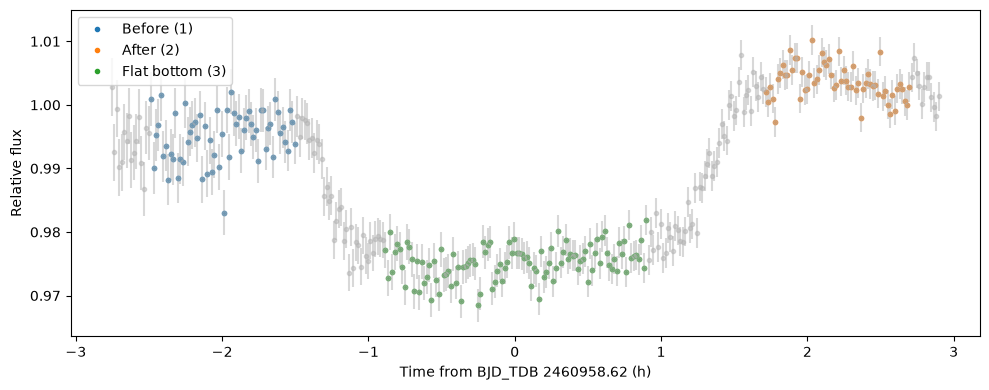

Outside: N = 120, mean = 0.999348, s = 0.005449
Inside:  N = 108, mean = 0.975255, s = 0.002709
Before vs. after: t = -13.811, p = 2.096e-26
Outside vs. inside (Eq. 4): t = 42.902, dof = 178.397
One-sided Gaussian approximation (Eq. 2): log10(alpha) = -401.709
One-sided Welch Student-t p = 3.178e-96


In [13]:
# By eye, pick a run of frames clearly before the transit (1), clearly after it (2), and clearly in the flat bottom (3).
before = (time >= -2.5) & (time <= -1.5)
after = (time >= 1.7) & (time <= 2.7)
bottom = (time >= -0.9) & (time <= 0.9)
outside = before | after

plt.figure(figsize=(10, 4))
plt.errorbar(time, flux, yerr=err, fmt=".", color="0.7", alpha=0.5)
for label, mask in [("Before (1)", before), ("After (2)", after),
                    ("Flat bottom (3)", bottom)]:
    plt.plot(time[mask], flux[mask], ".", label=label)
    print(f"{label}: N = {mask.sum()}, mean = {flux[mask].mean():.6f}, "
          f"s = {flux[mask].std(ddof=1):.6f}")
plt.xlabel(f"Time from BJD_TDB {bjd_ref:.2f} (h)")
plt.ylabel("Relative flux")
plt.legend()
plt.tight_layout()
plt.show()

# Out of transit and in transit are two "samples" with mean and standard deviation \mu_i and s_i. Compare with student's two-sample test
out_flux, in_flux = flux[outside], flux[bottom]
mu_out, mu_in = out_flux.mean(), in_flux.mean()
s_out, s_in = out_flux.std(ddof=1), in_flux.std(ddof=1)
n_out, n_in = len(out_flux), len(in_flux)
t_student = abs(mu_out - mu_in) / np.sqrt(s_out**2 / n_out + s_in**2 / n_in)
student_result = ttest_ind(out_flux, in_flux, equal_var=False, alternative="greater")
student_dof = student_result.df
log10_alpha_student_gaussian = log_ndtr(-t_student) / np.log(10)
baseline_result = ttest_ind(flux[before], flux[after], equal_var=True)
print(f"Outside: N = {n_out}, mean = {mu_out:.6f}, s = {s_out:.6f}")
print(f"Inside:  N = {n_in}, mean = {mu_in:.6f}, s = {s_in:.6f}")
print(f"Before vs. after: t = {baseline_result.statistic:.3f}, p = {baseline_result.pvalue:.3e}")
print(f"Outside vs. inside (Eq. 4): t = {t_student:.3f}, dof = {student_dof:.3f}")
print(f"One-sided Gaussian approximation (Eq. 2): log10(alpha) = {log10_alpha_student_gaussian:.3f}")
print(f"One-sided Welch Student-t p = {student_result.pvalue:.3e}")


##### 1.2 Written

The t test should be one-sided because we are testing for a planetary *transit*, which means that the flux inside the chosen window should be *less* than outside it; we know that direction before looking at the data. Using the formula in Eq. (4), $t = 42.902$. The one-sided Gaussian approximation from Eq. (2) gives $\log_{10}\alpha = -401.709$ (about $2 \times 10^{-402}$). Using the finite-sample Welch Student-t distribution instead gives $\alpha = 3.18 \times 10^{-96}$. Either way, we have highly significant evidence against equal in- and out-of-transit means under the test's assumptions.


#### Part 1.3

Best t0 = -0.15292 h from BJD_TDB 2460958.62
Best mid-transit BJD_TDB = 2460958.61362833
Out-of-transit level = 1.001274
delta = 0.022267 +/- 0.000287
chi^2_box = 1707.62, dof = 337, reduced chi^2 = 5.067
Delta chi^2 = 5867.76
(delta / sigma_delta)^2 = 6017.57
Student t from 1.2 = 42.902, t^2 = 1840.58
sqrt(Delta chi^2) = 76.601, delta / sigma_delta = 77.573


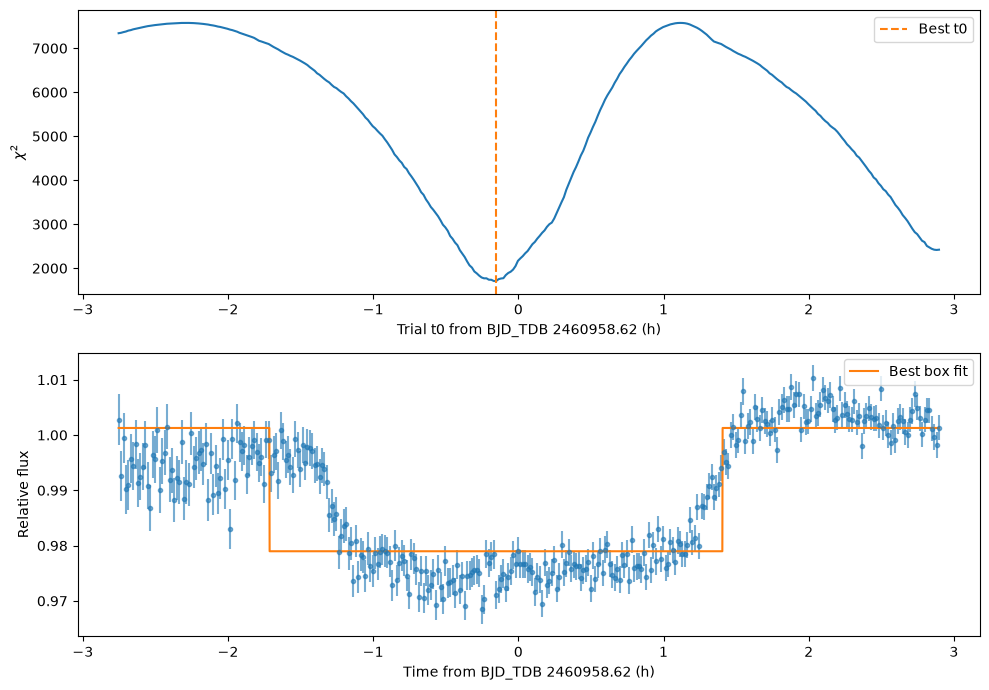

In [14]:
# Fit the level and fractional depth at each trial mid-transit time.
T = 3.12  # hours
trial_t0 = time.min() + np.arange(int(np.floor(np.ptp(time) * 60)) + 1) / 60
box_params = np.empty((len(trial_t0), 2))
box_cov = np.empty((len(trial_t0), 2, 2))
chi2_grid = np.empty(len(trial_t0))

def box_model(t, level, delta, t0):
    in_transit = np.abs(t - t0) <= T / 2
    return level * (1 - delta * in_transit)

for i, t0 in enumerate(trial_t0):
    def fixed_box(t, level, delta):
        return box_model(t, level, delta, t0)

    box_params[i], box_cov[i] = curve_fit(
        fixed_box, time, flux, p0=[1.0, 0.02], sigma=err, absolute_sigma=True)
    chi2_grid[i] = np.sum(((flux - fixed_box(time, *box_params[i])) / err)**2)

best = np.argmin(chi2_grid)
best_t0 = trial_t0[best]
best_level, delta = box_params[best]
sigma_delta = np.sqrt(box_cov[best, 1, 1])  # conditional on best t0
chi2_box = chi2_grid[best]
dof_box = len(flux) - 3  # level, depth, and selected mid-transit time
delta_chi2 = chi2_const - chi2_box
print(f"Best t0 = {best_t0:.5f} h from BJD_TDB {bjd_ref:.2f}")
print(f"Best mid-transit BJD_TDB = {bjd_ref + best_t0 / 24:.8f}")
print(f"Out-of-transit level = {best_level:.6f}")
print(f"delta = {delta:.6f} +/- {sigma_delta:.6f}")
print(f"chi^2_box = {chi2_box:.2f}, dof = {dof_box}, reduced chi^2 = {chi2_box / dof_box:.3f}")
print(f"Delta chi^2 = {delta_chi2:.2f}")
print(f"(delta / sigma_delta)^2 = {(delta / sigma_delta)**2:.2f}")
print(f"Student t from 1.2 = {t_student:.3f}, t^2 = {t_student**2:.2f}")
print(f"sqrt(Delta chi^2) = {np.sqrt(delta_chi2):.3f}, delta / sigma_delta = {delta / sigma_delta:.3f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 7))
axes[0].plot(trial_t0, chi2_grid)
axes[0].axvline(best_t0, color="C1", linestyle="--", label="Best t0")
axes[0].set_xlabel(f"Trial t0 from BJD_TDB {bjd_ref:.2f} (h)")
axes[0].set_ylabel(r"$\chi^2$")
axes[0].legend()
model_time = np.linspace(time.min(), time.max(), 3000)
axes[1].errorbar(time, flux, yerr=err, fmt=".", alpha=0.6)
axes[1].plot(model_time, box_model(model_time, best_level, delta, best_t0),
             color="C1", label="Best box fit")
axes[1].set_xlabel(f"Time from BJD_TDB {bjd_ref:.2f} (h)")
axes[1].set_ylabel("Relative flux")
axes[1].legend()
fig.tight_layout()
plt.show()

##### 1.3 Written

As shown above, the best $t_0$ is -0.15292 h from BJD_TDB 2460958.62 (i.e. 0.15292 h before our reference time), with $\delta = 0.022267 \pm 0.000287$. We get $\Delta\chi^2 = 5867.76$, compared with $(\delta/\sigma_\delta)^2 = 6017.57$, so they agree to about 2.6%; using a fractional depth relative to a fitted baseline makes the equality approximate. To compare these with Q1.2 on the same scale, $\sqrt{\Delta\chi^2} = 76.60$ and $\delta/\sigma_\delta = 77.57$, versus $t = 42.90$ (or $t^2 = 1840.58$ on the squared scale). The box uses all frames and their supplied errors, while Q1.2 uses the measured scatter in selected runs, so the significances need not agree. For the best box, $\chi_\nu^2 = 5.067$, suggesting that the box model is still underspecified or that the noise assumptions are incomplete.


### Problem 2

#### Part 2.1

f0: 1.001220 +/- 0.000222
delta: 0.025400 +/- 0.000312
t0 (h): -0.006291 +/- 0.006697
T (h): 3.074407 +/- 0.026998
tau (h): 0.461211 +/- 0.022715
chi^2 = 660.80, dof = 335
Reduced chi^2 = 1.973


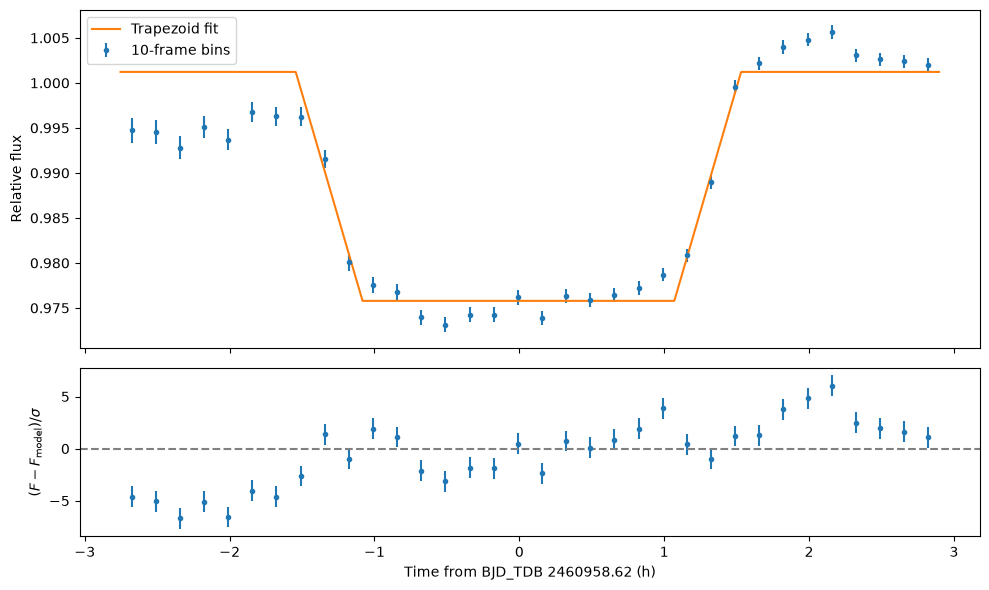

Correlation matrix, in order: f0, delta, t0 (h), T (h), tau (h)
[[ 1.     0.692 -0.     0.298  0.177]
 [ 0.692  1.    -0.     0.206  0.253]
 [-0.    -0.     1.    -0.137 -0.018]
 [ 0.298  0.206 -0.137  1.     0.845]
 [ 0.177  0.253 -0.018  0.845  1.   ]]


In [15]:
# Define a trapezoidal model for the transit
def trapezoid(t, f0, delta, t0, T, tau):
    """Relative flux of a star with out-of-transit level f0, dimmed by
    the fractional depth delta for a total duration T centered on t0,
    with an ingress and an egress that each last tau."""
    transit_shape = np.clip((T / 2 - np.abs(np.asarray(t) - t0)) / tau, 0, 1)
    return f0 * (1 - delta * transit_shape)

# fit with curve fit with both sigma and absolute sigma = True.
# Try several starts because the contact points make the fit piecewise smooth.
trap_fits = []
for center_guess in [best_t0, 0.0]:
    for ingress_guess in [0.2, 0.4, 0.6]:
        params, covariance = curve_fit(
            trapezoid, time, flux, sigma=err, absolute_sigma=True,
            p0=[best_level, delta, center_guess, 3.12, ingress_guess],
            bounds=([0, 0, time.min(), 0, 1e-8],
                    [np.inf, 1, time.max(), np.inf, np.inf]), max_nfev=10000)
        if 0 < params[4] < params[3] / 2:
            chi2 = np.sum(((flux - trapezoid(time, *params)) / err)**2)
            trap_fits.append((chi2, params, covariance))
_, trap_params, trap_cov = min(trap_fits, key=lambda fit: fit[0])
assert 0 < trap_params[4] < trap_params[3] / 2
trap_model = trapezoid(time, *trap_params)
trap_residuals = (flux - trap_model) / err
trap_chi2 = np.sum(trap_residuals**2)
trap_dof = len(flux) - len(trap_params)

# report parameters with uncertainty and $\chi_\nu^2$ (each)
param_names = ["f0", "delta", "t0 (h)", "T (h)", "tau (h)"]
trap_sigma = np.sqrt(np.diag(trap_cov))
for name, value, sigma in zip(param_names, trap_params, trap_sigma):
    print(f"{name}: {value:.6f} +/- {sigma:.6f}")
print(f"chi^2 = {trap_chi2:.2f}, dof = {trap_dof}")
print(f"Reduced chi^2 = {trap_chi2 / trap_dof:.3f}")

# Plot data, binned in groups of 10, with model above and normalized residuals below
bin_starts = np.arange(0, len(time), 10)
weights = 1 / err**2
bin_weights = np.add.reduceat(weights, bin_starts)
bin_time = np.add.reduceat(weights * time, bin_starts) / bin_weights
bin_flux = np.add.reduceat(weights * flux, bin_starts) / bin_weights
bin_err = 1 / np.sqrt(bin_weights)
# Average the model over the same observations as each bin.
bin_model = np.add.reduceat(weights * trap_model, bin_starts) / bin_weights
bin_residuals = (bin_flux - bin_model) / bin_err

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 6),
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].errorbar(bin_time, bin_flux, yerr=bin_err, fmt=".", label="10-frame bins")
fine_time = np.linspace(time.min(), time.max(), 2000)
axes[0].plot(fine_time, trapezoid(fine_time, *trap_params), label="Trapezoid fit")
axes[0].set_ylabel("Relative flux")
axes[0].legend()
axes[1].errorbar(bin_time, bin_residuals, yerr=np.ones_like(bin_err), fmt=".")
axes[1].axhline(0, color="0.5", linestyle="--")
axes[1].set_ylabel(r"$(F - F_{\rm model}) / \sigma$")
axes[1].set_xlabel(f"Time from BJD_TDB {bjd_ref:.2f} (h)")
fig.tight_layout()
plt.show()

# Calculate correlation matrix *from* covariance matrix
trap_corr = trap_cov / np.outer(trap_sigma, trap_sigma)
print("Correlation matrix, in order:", ", ".join(param_names))
with np.printoptions(precision=3, suppress=True):
    print(trap_corr)


##### 2.1 Written

The two most strongly correlated parameters are $T$ and $\tau$. Increasing both can keep the flat-bottom half-width, $T/2 - \tau$, roughly fixed, so the model can trade a longer total duration against longer ramps while preserving much of the same shape. The parameter $t_0$ is correlated with almost nothing because shifting a symmetric transit moves ingress and egress together: it raises the model on one side while lowering it on the other. Changing the depth or durations changes the two sides symmetrically, so these effects mostly separate when both sides are observed.


#### Part 2.2

Retained 200000 samples; mean acceptance fraction = 0.547
f0: autocorrelation time = 49.8 steps, retained length / autocorrelation time = 80.3
delta: autocorrelation time = 48.7 steps, retained length / autocorrelation time = 82.2
t0 (h): autocorrelation time = 51.7 steps, retained length / autocorrelation time = 77.4
T (h): autocorrelation time = 50.8 steps, retained length / autocorrelation time = 78.7
tau (h): autocorrelation time = 49.9 steps, retained length / autocorrelation time = 80.2


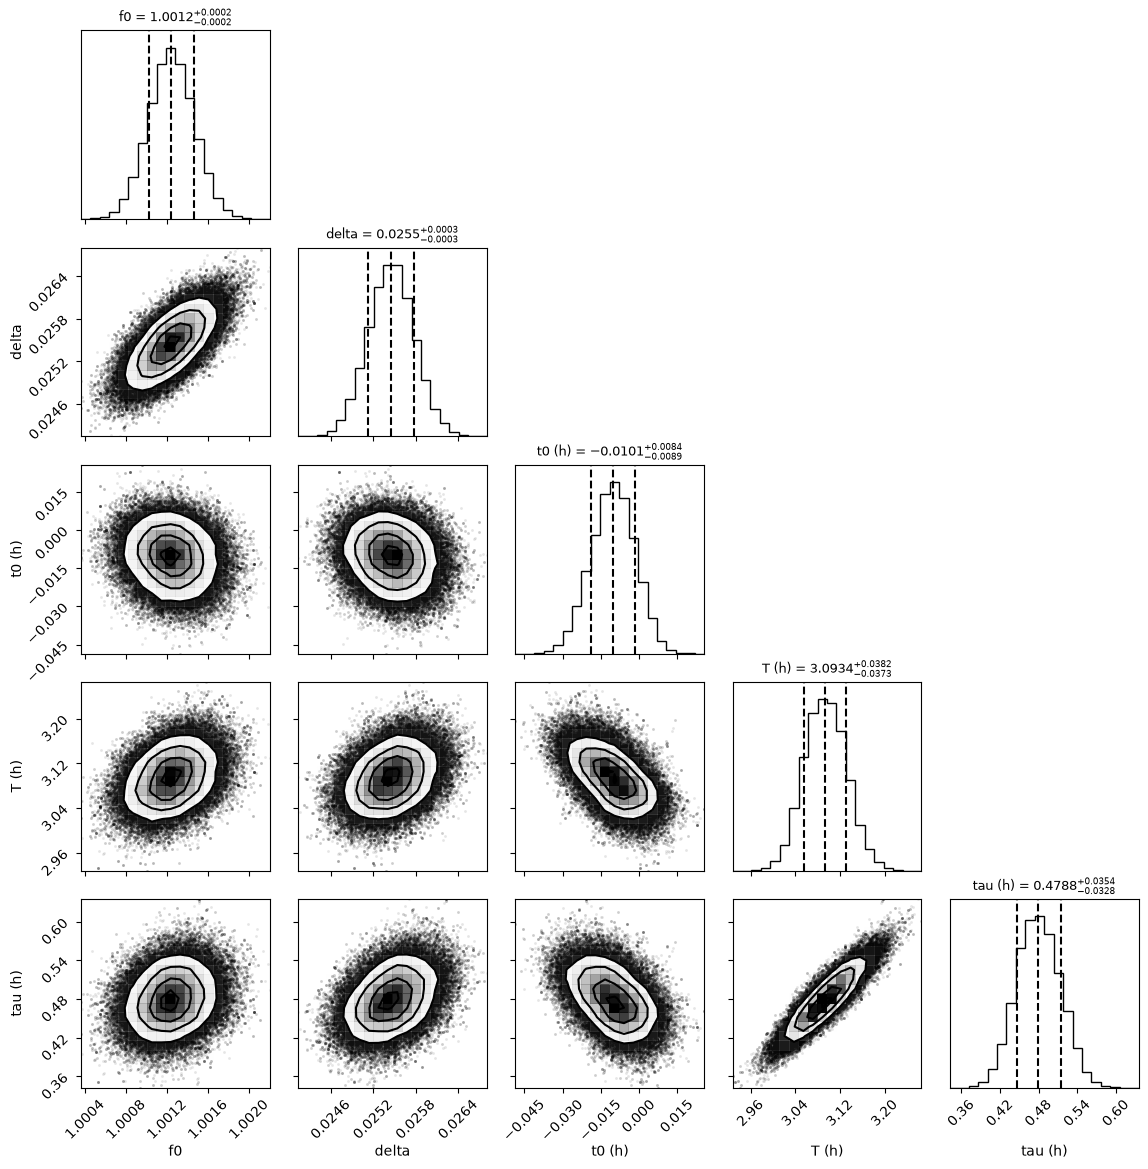

f0: 1.001239 (16th = 1.001018, 84th = 1.001462)
delta: 0.025451 (16th = 0.025129, 84th = 0.025773)
t0 (h): -0.010098 (16th = -0.018996, 84th = -0.001664)
T (h): 3.093423 (16th = 3.056078, 84th = 3.131621)
tau (h): 0.478848 (16th = 0.446026, 84th = 0.514217)


In [16]:
# Map whole posterior with emcee
# Install emcee and corner in the notebook environment if needed.
import emcee
import corner

# Use log-likelihood $-\chi^2/2$ and uniform priors across what is
# physically possible: $\delta > 0, T > 0, \frac T 2 > \tau > 0$
def log_probability(params):
    f0, depth, center, duration, ingress = params
    if not (np.all(np.isfinite(params)) and f0 > 0 and 0 < depth < 1
            and duration > 0 and 0 < ingress < duration / 2):
        return -np.inf
    residuals = (flux - trapezoid(time, *params)) / err
    return -0.5 * np.sum(residuals**2)

# Run 50 walkers for 5000 steps, discard the first 1000, and make a corner plot.
nwalkers, nsteps, burn_in = 50, 5000, 1000
ndim = len(trap_params)
rng = np.random.default_rng(7)
initial = rng.multivariate_normal(trap_params, trap_cov * 0.01, size=nwalkers)
for i in range(nwalkers):
    while not np.isfinite(log_probability(initial[i])):
        initial[i] = rng.multivariate_normal(trap_params, trap_cov * 0.01)
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
sampler.random_state = np.random.RandomState(7).get_state()
sampler.run_mcmc(initial, nsteps, progress=False)
samples = sampler.get_chain(discard=burn_in, flat=True)
print(f"Retained {len(samples)} samples; mean acceptance fraction = "
      f"{sampler.acceptance_fraction.mean():.3f}")

# Check the chain length against the estimated autocorrelation time.
autocorr = sampler.get_autocorr_time(discard=burn_in, tol=0)
for name, ac_time in zip(param_names, autocorr):
    print(f"{name}: autocorrelation time = {ac_time:.1f} steps, "
          f"retained length / autocorrelation time = {(nsteps - burn_in) / ac_time:.1f}")
if np.any(nsteps - burn_in < 50 * autocorr):
    print("Some parameters have fewer than 50 autocorrelation times; a longer run would help.")

fig = corner.corner(samples, labels=param_names, quantiles=[0.16, 0.5, 0.84],
                    show_titles=True, title_fmt=".4f",
                    title_kwargs={"fontsize": 9}, label_kwargs={"fontsize": 10})
fig.set_size_inches(12, 12)
fig.subplots_adjust(wspace=0.15, hspace=0.15)
plt.show()

# Report each parameter as the median with the 16th and 84th percentiles.
percentiles = np.percentile(samples, [16, 50, 84], axis=0)
for name, low, median, high in zip(param_names, *percentiles):
    print(f"{name}: {median:.6f} "
          f"(16th = {low:.6f}, 84th = {high:.6f})")


##### 2.2 Written

As a reminder, we got the following values from Q2.1:

1. f0: 1.001220 +/- 0.000222
2. delta: 0.025400 +/- 0.000312
3. t0 (h): -0.006291 +/- 0.006697
4. T (h): 3.074407 +/- 0.026998
5. tau (h): 0.461211 +/- 0.022715

All of our parameter values agree within the stated errors. The errors themselves (average of 84th - 50th and 50th - 16th percentile for MCMC, and the covariance errors for Q2.1) are larger for $t_0$, $T$ and $\tau$ in Q2.2, while f0 and delta have similar errors in both methods. So the local quadratic approximation to $\chi^2$ is less accurate over the uncertainty range for the timing and duration parameters. The trapezoid's contact points make that surface piecewise smooth. Similar errors do not imply weak correlations: f0 and delta themselves have a correlation of about 0.69, and the covariance matrix already includes local correlations. The light curve is not consistent with $\tau = 0$; even the MCMC 16th percentile is about 0.446 h, so it resolves the ingress under this model.


### Problem 3

#### Part 3.1

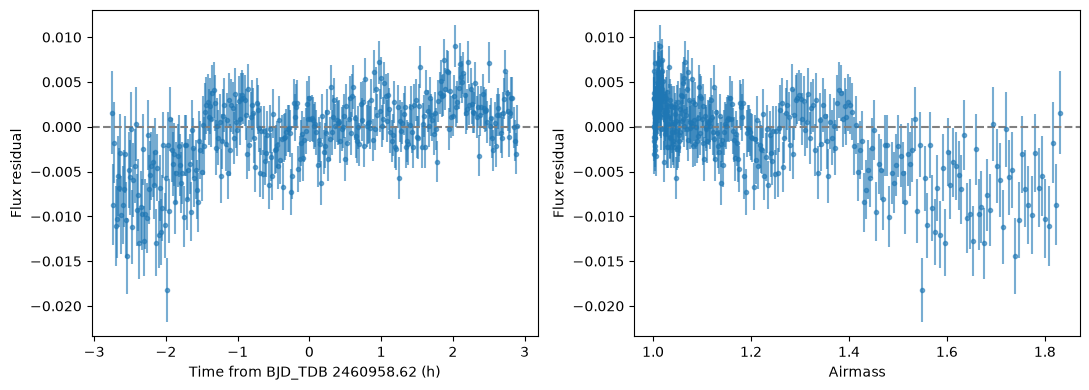

,chi^2,Reduced chi^2,BIC,delta,t0 (h),T (h),Delta BIC
Model,,,,,,,
Constant,660.805,1.973,689.949,0.025400 +/- 0.000312,-0.006291 +/- 0.006697,3.074407 +/- 0.026998,270.674
Time,391.021,1.171,425.995,0.023518 +/- 0.000325,0.042710 +/- 0.007098,2.974049 +/- 0.028079,6.719
Airmass,384.302,1.151,419.275,0.025325 +/- 0.000309,0.040282 +/- 0.006729,3.004568 +/- 0.026475,0.000


Preferred model: Airmass


,delta shift / first sigma,delta shift / second sigma,t0 shift / first sigma,t0 shift / second sigma
Change,,,,
Constant -> Time,-6.037,-5.796,7.317,6.904
Constant -> Airmass,-0.241,-0.243,6.954,6.921
Time -> Airmass,5.565,5.851,-0.342,-0.361


In [17]:
# Look for structure left by the constant-baseline trapezoid.
import pandas as pd
from IPython.display import display

residual_const = flux - trap_model
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, x, label in zip(axes, [time, airmass],
                         [f"Time from BJD_TDB {bjd_ref:.2f} (h)", "Airmass"]):
    ax.errorbar(x, residual_const, yerr=err, fmt=".", alpha=0.6)
    ax.axhline(0, color="0.5", linestyle="--")
    ax.set_xlabel(label)
    ax.set_ylabel("Flux residual")
fig.tight_layout()
plt.show()

# Multiply the trapezoid by each baseline from Eq. (7).
def time_baseline(x, f0, depth, center, duration, ingress, c):
    t, X = x
    return trapezoid(t, f0, depth, center, duration, ingress) * (1 + c * t)

def air_baseline(x, f0, depth, center, duration, ingress, c):
    t, X = x
    return trapezoid(t, f0, depth, center, duration, ingress) * (1 + c * (X - 1))

baseline_x = np.array([time, airmass])
baseline_bounds = ([0, 0, time.min(), 0, 1e-8, -np.inf],
                   [np.inf, 1, time.max(), np.inf, np.inf, np.inf])
model_fits = {"Constant": {"params": trap_params.copy(), "cov": trap_cov.copy(),
                           "prediction": trap_model.copy(), "function": None}}
for name, function in [("Time", time_baseline), ("Airmass", air_baseline)]:
    candidates = []
    for center_guess in [trap_params[2], 0.0]:
        for ingress_guess in [0.2, 0.4, 0.6]:
            guess = np.r_[trap_params, 0.0]
            guess[2], guess[4] = center_guess, ingress_guess
            fit_params, fit_cov = curve_fit(
                function, baseline_x, flux, p0=guess, sigma=err, absolute_sigma=True,
                bounds=baseline_bounds, max_nfev=10000,
                ftol=1e-11, xtol=1e-11, gtol=1e-11)
            if 0 < fit_params[4] < fit_params[3] / 2:
                prediction = function(baseline_x, *fit_params)
                fit_chi2 = np.sum(((flux - prediction) / err)**2)
                candidates.append((fit_chi2, fit_params, fit_cov, prediction))
    _, fit_params, fit_cov, prediction = min(candidates, key=lambda fit: fit[0])
    model_fits[name] = {"params": fit_params, "cov": fit_cov,
                        "prediction": prediction, "function": function}

# Use all the unbinned frames for chi^2 and BIC.
comparison_rows = []
for name, fit in model_fits.items():
    fit["sigma"] = np.sqrt(np.diag(fit["cov"]))
    fit["chi2"] = np.sum(((flux - fit["prediction"]) / err)**2)
    fit["dof"] = len(flux) - len(fit["params"])
    fit["bic"] = fit["chi2"] + len(fit["params"]) * np.log(len(flux))
    values, errors = fit["params"], fit["sigma"]
    comparison_rows.append({
        "Model": name, "chi^2": round(fit["chi2"], 3),
        "Reduced chi^2": round(fit["chi2"] / fit["dof"], 3),
        "BIC": round(fit["bic"], 3),
        "delta": f"{values[1]:.6f} +/- {errors[1]:.6f}",
        "t0 (h)": f"{values[2]:.6f} +/- {errors[2]:.6f}",
        "T (h)": f"{values[3]:.6f} +/- {errors[3]:.6f}"})
comparison = pd.DataFrame(comparison_rows).set_index("Model")
preferred_name = min(model_fits, key=lambda name: model_fits[name]["bic"])
preferred_fit = model_fits[preferred_name]
comparison["Delta BIC"] = [round(model_fits[name]["bic"] - preferred_fit["bic"], 3)
                           for name in comparison.index]
display(comparison)
print("Preferred model:", preferred_name)

# Give each shift in units of both models' own uncertainties.
shift_rows = []
for first, second in [("Constant", "Time"), ("Constant", "Airmass"), ("Time", "Airmass")]:
    a, b = model_fits[first], model_fits[second]
    row = {"Change": f"{first} -> {second}"}
    for index, label in [(1, "delta"), (2, "t0")]:
        shift = b["params"][index] - a["params"][index]
        row[f"{label} shift / first sigma"] = round(shift / a["sigma"][index], 3)
        row[f"{label} shift / second sigma"] = round(shift / b["sigma"][index], 3)
    shift_rows.append(row)
display(pd.DataFrame(shift_rows).set_index("Change"))


##### 3.1 Written

There is definitely structure: the residuals tend to be negative early in the night and positive late in the night, and they also track airmass. The constant baseline is missing a slow drift.

The airmass model wins, with BIC = 419.28, compared with 425.99 for time and 689.95 for the constant baseline. So it beats time by 6.72 (a strong preference by the stated rule), and constant by 270.67.

Using each new model's own uncertainty, constant --> time moves $\delta$ down by 5.80 sigma and $t_0$ up by 6.90 sigma. Constant --> airmass moves $\delta$ down by only 0.24 sigma, but $t_0$ up by 6.92 sigma. Time --> airmass moves $\delta$ up by 5.85 sigma and $t_0$ down by 0.36 sigma. The table also gives these shifts using the first model's errors.

A tilt mostly trades off with $t_0$: changing which side of the transit is relatively high can make ingress and egress look shifted. A bend mostly trades off with $\delta$, because it changes where the baseline would sit under the middle of the transit. Airmass is curved as a function of time, so the time and airmass models can agree pretty well on $t_0$ while giving appreciably different depths. The separation is not exact; both baseline choices can affect both parameters.

#### Part 3.2

Mean beta for 10-30 frames = 1.580
Scatter / white prediction at 3, 10, 20, 30 frames: 1.16, 1.43, 1.79, 1.73


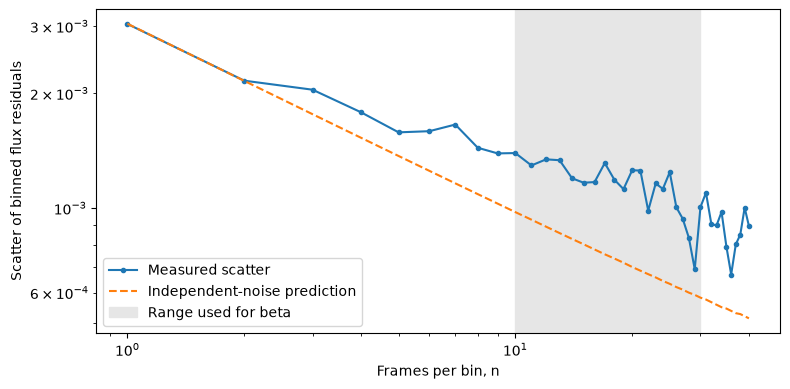

In [18]:
# Bin the preferred model's flux residuals and compare with Eq. (8).
preferred_residuals = flux - preferred_fit["prediction"]
bin_sizes = np.arange(1, 41)
scatter = np.empty(len(bin_sizes))
white_scatter = np.empty(len(bin_sizes))
sigma1 = np.std(preferred_residuals, ddof=1)
for i, size in enumerate(bin_sizes):
    M = len(flux) // size
    # Only use complete groups; don't mix a shorter last bin into the scatter.
    grouped = preferred_residuals[:M * size].reshape(M, size).mean(axis=1)
    scatter[i] = np.std(grouped, ddof=1)
    white_scatter[i] = sigma1 / np.sqrt(size) * np.sqrt(M / (M - 1))

beta_by_size = scatter / white_scatter
beta = beta_by_size[(bin_sizes >= 10) & (bin_sizes <= 30)].mean()
print(f"Mean beta for 10-30 frames = {beta:.3f}")
print(f"Scatter / white prediction at 3, 10, 20, 30 frames: "
      f"{beta_by_size[2]:.2f}, {beta_by_size[9]:.2f}, "
      f"{beta_by_size[19]:.2f}, {beta_by_size[29]:.2f}")

plt.figure(figsize=(8, 4))
plt.loglog(bin_sizes, scatter, ".-", label="Measured scatter")
plt.loglog(bin_sizes, white_scatter, "--", label="Independent-noise prediction")
plt.axvspan(10, 30, color="0.9", label="Range used for beta", zorder=0)
plt.xlabel("Frames per bin, n")
plt.ylabel("Scatter of binned flux residuals")
plt.legend()
plt.tight_layout()
plt.show()


##### 3.2 Written

The curves are close for 1-2 frames, but the measured scatter starts pulling above the white-noise prediction around 3-6 frames. The excess is pretty clear by about 7-10 frames, though it jumps around because the larger bin sizes leave fewer bins. So neighboring residuals are not independent. Averaging the ratio from 10 to 30 gives $\beta = 1.58$.

Multiplying all the errors by the same number just divides the whole $\chi^2$ surface by $\beta^2$, so the best-fit values should stay put. The uncertainties should all grow by $\beta$ since we are using `absolute_sigma=True`.

In [19]:
# Inflate the errors and actually refit the preferred model.
scaled_err = beta * err
refit_params, refit_cov = curve_fit(
    preferred_fit["function"], baseline_x, flux, p0=preferred_fit["params"],
    sigma=scaled_err, absolute_sigma=True, bounds=baseline_bounds, max_nfev=10000,
    ftol=1e-11, xtol=1e-11, gtol=1e-11)
refit_sigma = np.sqrt(np.diag(refit_cov))
refit_prediction = preferred_fit["function"](baseline_x, *refit_params)
refit_chi2 = np.sum(((flux - refit_prediction) / scaled_err)**2)
refit_rows = []
for i, name in enumerate(["f0", "delta", "t0 (h)", "T (h)", "tau (h)", "c"]):
    refit_rows.append({"Parameter": name,
                       "Original value": preferred_fit["params"][i],
                       "Refit value": refit_params[i],
                       "Original sigma": preferred_fit["sigma"][i],
                       "Refit sigma": refit_sigma[i],
                       "Sigma ratio": refit_sigma[i] / preferred_fit["sigma"][i]})
display(pd.DataFrame(refit_rows).set_index("Parameter").round(6))
print(f"Reduced chi^2 before inflation = {preferred_fit['chi2'] / preferred_fit['dof']:.3f}")
print(f"Reduced chi^2 after inflation = {refit_chi2 / preferred_fit['dof']:.3f}")


,Original value,Refit value,Original sigma,Refit sigma,Sigma ratio
Parameter,,,,,
f0,1.003385,1.003385,0.000257,0.000406,1.579755
delta,0.025325,0.025325,0.000309,0.000488,1.579755
t0 (h),0.040282,0.040282,0.006729,0.010630,1.579755
T (h),3.004568,3.004568,0.026475,0.041824,1.579755
tau (h),0.419614,0.419614,0.022151,0.034993,1.579755
c,-0.013843,-0.013843,0.000816,0.001289,1.579755


Reduced chi^2 before inflation = 1.151
Reduced chi^2 after inflation = 0.461


##### 3.2 Written (again)

As expected, none of the parameter values change appreciably, and all six uncertainties grow by about 1.58. In particular, $\delta = 0.025325 \pm 0.000488$, $t_0 = 0.04028 \pm 0.01063$ h, and $T = 3.00457 \pm 0.04182$ h.

The original unbinned reduced $\chi^2$ was only 1.151, which is close to $1$ but misses the correlations. After scaling, it is about 0.461. We are correcting the errors on transit-length timescales, so making the unbinned reduced $\chi^2$ equal to one is not the goal here. That one number was not a good guide to whether the parameter errors were right. This scaling is still an approximate way to handle correlated noise.

In [20]:
# Literature values supplied in Q3.3; keep times in hours from bjd_ref.
from scipy.special import erfc

literature_T0, literature_sigma_T0 = 2455867.402743, 0.000049  # days
period, sigma_period = 2.15000820, 0.00000013  # days
radius_ratio, sigma_radius_ratio = 0.14886, 0.00056
literature_duration, sigma_duration = 3.120, 0.012  # hours

measured_bjd = bjd_ref + refit_params[2] / 24
orbit_number = int(np.rint((measured_bjd - literature_T0) / period))
predicted_bjd = literature_T0 + orbit_number * period
sigma_predicted_days = np.hypot(literature_sigma_T0, orbit_number * sigma_period)
predicted_t0 = 24 * (predicted_bjd - bjd_ref)
sigma_predicted_t0 = 24 * sigma_predicted_days
predicted_depth = radius_ratio**2
sigma_predicted_depth = 2 * radius_ratio * sigma_radius_ratio
print(f"Orbit number = {orbit_number}")
print(f"Predicted mid-transit BJD = {predicted_bjd:.8f} +/- {sigma_predicted_days:.8f}")
print(f"Predicted t0 = {predicted_t0:.6f} +/- {sigma_predicted_t0:.6f} h")
print(f"Predicted depth = {predicted_depth:.6f} +/- {sigma_predicted_depth:.6f}")

# Combine measurement and literature errors, then use the two-tailed Eq. (2).
test_rows = []
for label, index, expected, expected_sigma in [
        ("t0 (h)", 2, predicted_t0, sigma_predicted_t0),
        ("delta", 1, predicted_depth, sigma_predicted_depth),
        ("T (h)", 3, literature_duration, sigma_duration)]:
    total_sigma = np.hypot(refit_sigma[index], expected_sigma)
    test_t = (refit_params[index] - expected) / total_sigma
    alpha = erfc(abs(test_t) / np.sqrt(2))
    if alpha < 0.01:
        conclusion = "Reject H0 (highly significant)"
    elif alpha < 0.05:
        conclusion = "Reject H0 (significant)"
    else:
        conclusion = "Do not reject H0"
    test_rows.append({"Parameter": label,
                      "Measured": f"{refit_params[index]:.6f} +/- {refit_sigma[index]:.6f}",
                      "Predicted": f"{expected:.6f} +/- {expected_sigma:.6f}",
                      "t": round(test_t, 3), "alpha": f"{alpha:.3e}",
                      "Conclusion": conclusion})
display(pd.DataFrame(test_rows).set_index("Parameter"))


Orbit number = 2368
Predicted mid-transit BJD = 2460958.62216060 +/- 0.00031172
Predicted t0 = 0.051854 +/- 0.007481 h
Predicted depth = 0.022159 +/- 0.000167


,Measured,Predicted,t,alpha,Conclusion
Parameter,,,,,
t0 (h),0.040282 +/- 0.010630,0.051854 +/- 0.007481,-0.890,3.733e-01,Do not reject H0
delta,0.025325 +/- 0.000488,0.022159 +/- 0.000167,6.139,8.294e-10,Reject H0 (highly significant)
T (h),3.004568 +/- 0.041824,3.120000 +/- 0.012000,-2.653,7.980e-03,Reject H0 (highly significant)


##### 3.3 Written

The right orbit is $n = 2368$, giving a predicted mid-transit time of BJD $2460958.6221606 \pm 0.0003117$, or $t_0 = 0.05185 \pm 0.00748$ h in our time system. We include the literature uncertainties when testing each prediction, and use two tails because an offset in either direction would count.

For timing, $t = -0.890$ and $\alpha = 0.373$, so we do not reject the predicted $t_0$. For depth, $t = 6.139$ and $\alpha = 8.29 \times 10^{-10}$, so the fitted depth is highly significantly larger than $(R_p/R_\star)^2 = 0.022159 \pm 0.000167$. For duration, $t = -2.653$ and $\alpha = 0.00798$, so the fitted duration is significantly shorter than 3.120 h (also below the handout's 0.01 threshold).

These discrepancies are not convincing new science. The trapezoid treats the fully covered part of the transit as flat, effectively ignoring limb darkening: a real star is brighter near its center than near its edge. So a flat-bottom depth does not have to equal just the area ratio, and straight ingress/egress ramps can also bias the duration. We also saw that changing a plausible baseline moves the depth by several sigma, and multiplying errors by $\beta$ does not fix an imperfect model. The small p-values test these simplified assumptions along with the literature prediction.

### AI Use Statement

I used AI in this problem set for the following tasks:

1. Help with importing frames from files.
2. Formatting of markdown text (bolding, writing e- properly, converting my shorthand formulas to their formal equivalents, and fixing my latex). AI was not used to actually write any discussion text or to make any claims.
3. Help with plotting libraries.
4. Writing coherent and efficient print statements
5. Determining if particular functions existed in numpy or astropy or matplotlib libraries, and quickly referencing the documentation of these functions.
